## A1 - So sánh CNN (ResNet-50) và Transformer (ViT-B/16) trên Food-101

- Dataset lựa chọn: **Food-101**
  - 101,000 ảnh màu, 101 lớp món ăn
  - Split chính thức: 750 ảnh train + 250 ảnh test mỗi lớp
  - Ảnh train có nhiễu (một số nhãn sai), ảnh test được kiểm tra thủ công

### Chuẩn bị dữ liệu và DataLoader

Dataset quá lớn để nạp hết vào bộ nhớ (~5 GB JPEG), nên chỉ giữ danh sách `(image_id, label)` và **đọc + decode từng ảnh** khi DataLoader cần.

In [1]:
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

sys.path.append(str(Path.cwd().parent))  # repo root -> `common`

from common.utils import set_seed, get_device
from common.plotting import setup_style, save_fig
from data import (
    SPLITS, read_classes, load_or_build_manifest, file_sha256, check_manifest,
    make_datasets, make_loaders, denormalize,
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| TorchVision:", torchvision.__version__, "| NumPy:", np.__version__)

Python: 3.11.1
PyTorch: 2.14.0 | TorchVision: 0.29.0 | NumPy: 2.4.6


In [3]:
# Config

CONFIG = {
    "dataset": "Food-101",
    "data_dir": Path("../../food-101"),
    "manifest_path": Path("split_manifest.csv"),
    "split_seed": 2026,      # per-class RNG: default_rng(split_seed + class_index)
    "per_class": {"train": 600, "val": 150, "test": 250},
    "image_size": 224,
    "physical_batch": 32,
    "accum_steps": 4,            # effective batch = 32 x 4 = 128
    "num_workers": 8,
    "seed": 42,                  # training seed (does not change the split)
}

set_seed(CONFIG["seed"])
DEVICE = get_device()
FIG_DIR = Path("figures")
setup_style()

assert (CONFIG["data_dir"] / "images").is_dir(), f"Food-101 not found at {CONFIG['data_dir'].resolve()}"
print("Device:", DEVICE)
print("Effective batch:", CONFIG["physical_batch"] * CONFIG["accum_steps"])

Device: mps
Effective batch: 128


In [5]:
# Classes (sorted lexicographically, index = position)

CLASS_NAMES = read_classes(CONFIG["data_dir"])
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SHAPE = (3, CONFIG["image_size"], CONFIG["image_size"])  # (C, H, W)

print("Number of classes:", NUM_CLASSES)
print("Image shape:", IMAGE_SHAPE)
print("First 5 classes:", CLASS_NAMES[:5])

Number of classes: 101
Image shape: (3, 224, 224)
First 5 classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']


#### Chia tập dữ liệu và manifest

- Validation chỉ lấy từ **split train chính thức**: mỗi lớp sắp xếp ID, hoán vị bằng `default_rng(2026 + class_index)`, 150 ảnh đầu vào validation, 600 ảnh còn lại vào train.
- Test giữ nguyên split chính thức (250 ảnh/lớp).
- Manifest lưu `image_id, class_index, split, sha256, width, height, mode`. Lần đầu chạy sẽ đọc toàn bộ ảnh để hash và kiểm tra decode (vài phút); các lần sau dùng lại file đã lưu.

| Partition | Ảnh/lớp | Tổng |
|-|-:|-:|
| Train | 600 | 60,600 |
| Validation | 150 | 15,150 |
| Test | 250 | 25,250 |

In [ ]:
# Dataset split

t0 = time.time()
manifest = load_or_build_manifest(
    CONFIG["manifest_path"], CONFIG["data_dir"], CLASS_NAMES,
    val_per_class=CONFIG["per_class"]["val"], split_seed=CONFIG["split_seed"],
)
print(f"Manifest rows: {len(manifest):,}  ({time.time() - t0:.1f}s)")
print("Manifest SHA-256:", file_sha256(CONFIG["manifest_path"]))

Manifest rows: 101,000  (17.4s)
Manifest SHA-256: c4027e1fb884a87bd71d8e649a73e8a55f824eeff30fd52ed8b69da643ca9e90


In [ ]:
# Thống kê kích thước ảnh có trong dataset về min/max của width và height.

widths = np.array([r["width"] for r in manifest if r["width"] > 0])
heights = np.array([r["height"] for r in manifest if r["height"] > 0])
short_edge = np.minimum(widths, heights)

print(f"Width : min {widths.min()}, median {np.median(widths):.0f}, max {widths.max()}")
print(f"Height: min {heights.min()}, median {np.median(heights):.0f}, max {heights.max()}")
print(f"Short edge < 224: {(short_edge < 224).sum()} images")

Width : min 193, median 512, max 512
Height: min 122, median 512, max 512
Short edge < 224: 14 images


#### Tiền xử lý và augmentation

Tất cả cấu hình dùng chung một pipeline:

- **Train:** `RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.75, 4/3))` → `RandomHorizontalFlip(0.5)`
- **Validation / Test:** resize cạnh ngắn về 256 → `CenterCrop(224)`
- Nội suy bilinear có antialias, đưa pixel về $[0, 1]$, chuẩn hoá theo mean/std của ImageNet
- Không dùng TTA, MixUp, CutMix hay label smoothing

In [ ]:
# Datasets & DataLoaders

datasets = make_datasets(manifest, CONFIG["data_dir"], CONFIG["image_size"])
loaders = make_loaders(
    datasets,
    batch_size=CONFIG["physical_batch"],
    seed=CONFIG["seed"],
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
)

for split in SPLITS:
    print(f"{split:5s}: {len(datasets[split]):6,} images, {len(loaders[split]):5,} batches")

train: 60,600 images, 1,894 batches
val  : 15,150 images,   474 batches
test : 25,250 images,   790 batches


In [11]:
# Loader throughput (decode + augmentation on CPU workers)

n_batches = 50
it = iter(loaders["train"])
next(it)  # warm up workers
t0 = time.time()
for _ in range(n_batches):
    next(it)
elapsed = time.time() - t0
print(f"Train loader: {n_batches * CONFIG['physical_batch'] / elapsed:.0f} images/s "
      f"({elapsed / n_batches * 1000:.0f} ms/batch, {CONFIG['num_workers']} workers)")

Train loader: 2419 images/s (13 ms/batch, 8 workers)


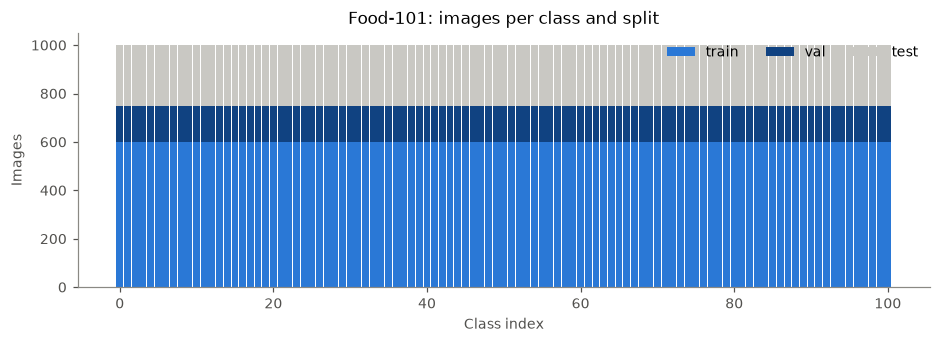

PosixPath('figures/class_distribution.png')

In [12]:
# Class distribution per split

fig, ax = plt.subplots(figsize=(10, 3))
x = np.arange(NUM_CLASSES)
bottom = np.zeros(NUM_CLASSES)
for split, color in zip(SPLITS, ["#2a78d6", "#104281", "#c9c8c3"]):
    counts = Counter(datasets[split].labels)
    heights_ = np.array([counts[c] for c in range(NUM_CLASSES)])
    ax.bar(x, heights_, bottom=bottom, color=color, label=split, width=0.9)
    bottom += heights_
ax.set_xlabel("Class index")
ax.set_ylabel("Images")
ax.set_title("Food-101: images per class and split")
ax.legend(frameon=False, ncol=3)
save_fig(fig, FIG_DIR, "class_distribution", show=True)

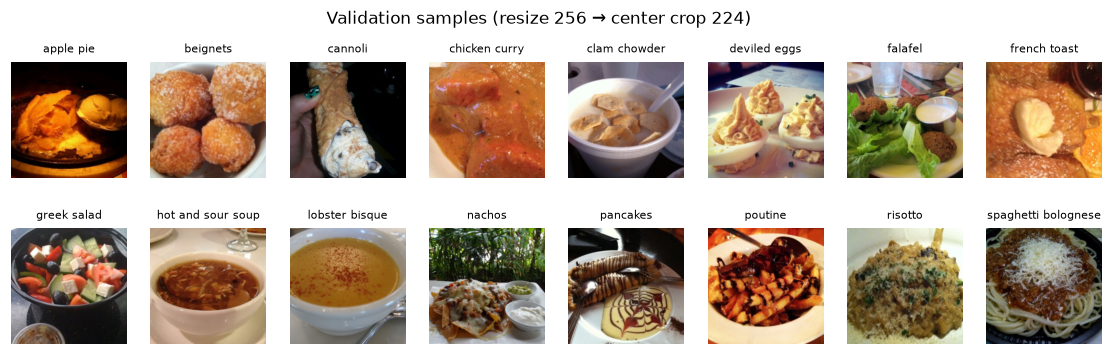

PosixPath('figures/samples_val.png')

In [14]:
# Sample images (one per class, validation transform)

def show_samples(dataset, n_classes=16, cols=8, title=""):
    first_of_class = {}
    for i, y in enumerate(dataset.labels):
        first_of_class.setdefault(y, i)
    idx = [first_of_class[c] for c in range(0, NUM_CLASSES, NUM_CLASSES // n_classes)][:n_classes]
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.8))
    for ax, i in zip(axes.flat, idx):
        img, y = dataset[i]
        ax.imshow(denormalize(img).permute(1, 2, 0).numpy())
        ax.set_title(CLASS_NAMES[y].replace("_", " "), fontsize=7)
        ax.axis("off")
    for ax in axes.flat[len(idx):]:
        ax.axis("off")
    fig.suptitle(title)
    return fig

fig = show_samples(datasets["val"], title="Validation samples (resize 256 → center crop 224)")
save_fig(fig, FIG_DIR, "samples_val", show=True)

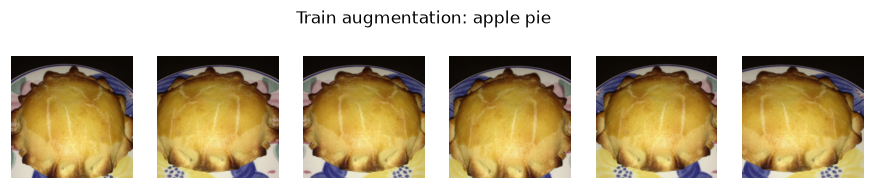

PosixPath('figures/augmentation_preview.png')

In [15]:
# Augmentation preview: the same training image under several random draws

img_idx = 0
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax in axes:
    img, y = datasets["train"][img_idx]
    ax.imshow(denormalize(img).permute(1, 2, 0).numpy())
    ax.axis("off")
fig.suptitle(f"Train augmentation: {CLASS_NAMES[y].replace('_', ' ')}")
save_fig(fig, FIG_DIR, "augmentation_preview", show=True)